# AAL Sales Analysis — Q4 2020 (Australia)

**Business ask (Head of Sales & Marketing):**
1. Identify the states generating the highest revenue.
2. Design sales programs for lower-revenue states.

This report covers **data wrangling → data analysis → data visualization (dashboard) → recommendations**.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import MinMaxScaler

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
money = mtick.FuncFormatter(lambda x, _: f"${x/1e6:.1f}M" if x >= 1e6 else f"${x/1e3:.0f}K")

df = pd.read_csv("../AusApparalSales4thQrt2020.csv")
print(df.shape)
df.head()

(7560, 6)


,Date,Time,State,Group,Unit,Sales
0,1-Oct-2020,Morning,WA,Kids,8,20000
1,1-Oct-2020,Morning,WA,Men,8,20000
2,1-Oct-2020,Morning,WA,Women,4,10000
3,1-Oct-2020,Morning,WA,Seniors,15,37500
4,1-Oct-2020,Afternoon,WA,Kids,3,7500


## 1. Data wrangling
### 1a. Inspect for missing or incorrect data with `isna()` / `notna()`

In [2]:
df.info()
print("\nMissing values per column (isna):\n", df.isna().sum())
print("\nNon-missing values per column (notna):\n", df.notna().sum())

<class 'pandas.DataFrame'>
RangeIndex: 7560 entries, 0 to 7559
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   Date    7560 non-null   str  
 1   Time    7560 non-null   str  
 2   State   7560 non-null   str  
 3   Group   7560 non-null   str  
 4   Unit    7560 non-null   int64
 5   Sales   7560 non-null   int64
dtypes: int64(2), str(4)
memory usage: 354.5 KB

Missing values per column (isna):
 Date     0
Time     0
State    0
Group    0
Unit     0
Sales    0
dtype: int64

Non-missing values per column (notna):
 Date     7560
Time     7560
State    7560
Group    7560
Unit     7560
Sales    7560
dtype: int64


In [3]:
# Text columns have leading spaces (e.g. ' WA') — strip them and parse dates
for c in ["Time", "State", "Group"]:
    df[c] = df[c].str.strip()
df["Date"] = pd.to_datetime(df["Date"], format="%d-%b-%Y")

print("Unique values:")
for c in ["Time", "State", "Group"]:
    print(f"  {c}: {sorted(df[c].unique())}")
print("Date range:", df["Date"].min().date(), "->", df["Date"].max().date(), f"({df['Date'].nunique()} days)")
print("Duplicate rows:", df.duplicated().sum())
print("Non-positive Unit/Sales:", ((df["Unit"] <= 0) | (df["Sales"] <= 0)).sum())
# Each unit is priced at a fixed $2,500
print("Sales / Unit ratio:", (df["Sales"] / df["Unit"]).unique())

Unique values:
  Time: ['Afternoon', 'Evening', 'Morning']
  State: ['NSW', 'NT', 'QLD', 'SA', 'TAS', 'VIC', 'WA']
  Group: ['Kids', 'Men', 'Seniors', 'Women']
Date range: 2020-10-01 -> 2020-12-30 (90 days)
Duplicate rows: 0
Non-positive Unit/Sales: 0
Sales / Unit ratio: [2500.]


### 1b. Treatment of missing / incorrect data — recommendation
* The data has **no missing values, no duplicates and no negative or zero entries**; every combination of
  90 days × 7 states × 4 groups × 3 time slots (7,560 rows) is present, and `Sales = Unit × $2,500` throughout.
* The only problems were **formatting**: leading spaces in text columns and dates stored as text — both fixed above.
* **Recommendation:** if nulls appear in future extracts, *fill* rather than drop. Because sales follow a fixed price,
  a missing `Sales` can be recomputed as `Unit × 2500` (and vice versa); otherwise use the median of the same State × Group × Time slot.
  Dropping rows would bias state/day totals because the dataset is a complete grid.

### 1c. Normalization (preferred over standardization)
Min-Max normalization rescales `Unit` and `Sales` to [0, 1], keeping the shape of the distribution and making the two columns comparable.

In [4]:
scaler = MinMaxScaler()
df[["Unit_norm", "Sales_norm"]] = scaler.fit_transform(df[["Unit", "Sales"]])
df[["Unit", "Sales", "Unit_norm", "Sales_norm"]].describe().round(3)

,Unit,Sales,Unit_norm,Sales_norm
count,7560.000,7560.000,7560.000,7560.000
mean,18.005,45013.558,0.254,0.254
std,12.901,32253.507,0.205,0.205
min,2.000,5000.000,0.000,0.000
25%,8.000,20000.000,0.095,0.095
50%,14.000,35000.000,0.190,0.190
75%,26.000,65000.000,0.381,0.381
max,65.000,162500.000,1.000,1.000


### 1d. Using `GroupBy()` for chunking vs. merging
`groupby()` *splits* data into chunks (split-apply-combine) — ideal for summarising by State, Group, Time, week or month.
Merging (`merge`/`join`) combines different tables. Here the data is one table, so **GroupBy chunking is the recommended approach**;
merging is only needed later to attach the aggregated results (e.g. state totals) back onto rows.

In [5]:
state_summary = df.groupby("State").agg(Total_Sales=("Sales", "sum"), Total_Units=("Unit", "sum"),
                                        Avg_Sale=("Sales", "mean")).sort_values("Total_Sales", ascending=False)
state_summary["Share_%"] = (state_summary["Total_Sales"] / state_summary["Total_Sales"].sum() * 100).round(1)
# Example of merging the aggregate back for row-level comparison
df = df.merge(state_summary[["Avg_Sale"]].rename(columns={"Avg_Sale": "State_Avg_Sale"}), on="State")
state_summary

,Total_Sales,Total_Units,Avg_Sale,Share_%
State,,,,
VIC,105565000,42226,97745.370370,31.0
NSW,74970000,29988,69416.666667,22.0
SA,58857500,23543,54497.685185,17.3
QLD,33417500,13367,30942.129630,9.8
TAS,22760000,9104,21074.074074,6.7
NT,22580000,9032,20907.407407,6.6
WA,22152500,8861,20511.574074,6.5


## 2. Data analysis
### 2a. Descriptive statistics for `Sales` and `Unit`

In [6]:
desc = pd.DataFrame({
    col: {"mean": df[col].mean(), "median": df[col].median(), "mode": df[col].mode().iloc[0],
          "std": df[col].std(), "min": df[col].min(), "max": df[col].max(),
          "skew": stats.skew(df[col]), "kurtosis": stats.kurtosis(df[col])}
    for col in ["Sales", "Unit"]}).round(2)
desc

,Sales,Unit
mean,45013.56,18.01
median,35000.00,14.00
mode,22500.00,9.00
std,32253.51,12.90
min,5000.00,2.00
max,162500.00,65.00
skew,1.09,1.09
kurtosis,0.66,0.66


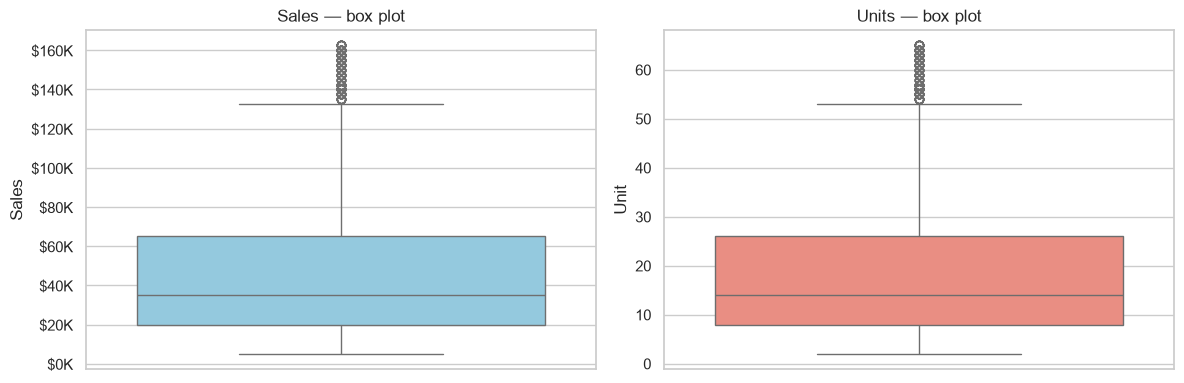

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(y=df["Sales"], ax=axes[0], color="skyblue"); axes[0].set_title("Sales — box plot"); axes[0].yaxis.set_major_formatter(money)
sns.boxplot(y=df["Unit"], ax=axes[1], color="salmon"); axes[1].set_title("Units — box plot")
plt.tight_layout(); plt.show()

Both columns are **right-skewed** (mean > median): most transactions are small, with a long tail of large sales, mostly from VIC and NSW.

### 2b/2c. Highest- and lowest-selling groups (by demographic group and by state)

In [8]:
group_sales = df.groupby("Group")["Sales"].sum().sort_values(ascending=False)
state_sales = df.groupby("State")["Sales"].sum().sort_values(ascending=False)
time_sales = df.groupby("Time")["Sales"].sum().sort_values(ascending=False)
print("Sales by Group:\n", group_sales, "\n")
print(f"Highest group: {group_sales.idxmax()} (${group_sales.max():,.0f}) | Lowest group: {group_sales.idxmin()} (${group_sales.min():,.0f})\n")
print("Sales by State:\n", state_sales, "\n")
print(f"Highest state: {state_sales.idxmax()} (${state_sales.max():,.0f}) | Lowest state: {state_sales.idxmin()} (${state_sales.min():,.0f})\n")
print("Sales by Time of day:\n", time_sales)

Sales by Group:
 Group
Men        85750000
Women      85442500
Kids       85072500
Seniors    84037500
Name: Sales, dtype: int64 

Highest group: Men ($85,750,000) | Lowest group: Seniors ($84,037,500)

Sales by State:
 State
VIC    105565000
NSW     74970000
SA      58857500
QLD     33417500
TAS     22760000
NT      22580000
WA      22152500
Name: Sales, dtype: int64 

Highest state: VIC ($105,565,000) | Lowest state: WA ($22,152,500)

Sales by Time of day:
 Time
Morning      114207500
Afternoon    114007500
Evening      112087500
Name: Sales, dtype: int64


In [9]:
# Is the difference between demographic groups statistically meaningful? (one-way ANOVA)
f, p = stats.f_oneway(*[g["Sales"] for _, g in df.groupby("Group")])
print(f"ANOVA across groups: F = {f:.2f}, p = {p:.3f}")
f, p = stats.f_oneway(*[g["Sales"] for _, g in df.groupby("State")])
print(f"ANOVA across states: F = {f:.2f}, p = {p:.3g}")

ANOVA across groups: F = 0.28, p = 0.838
ANOVA across states: F = 3662.59, p = 0


Demographic groups sell almost identical amounts (differences are not significant), whereas **states differ hugely**.
So the expansion decision should be driven by geography rather than by customer group.

### 2d. Weekly, monthly and quarterly reports

In [10]:
df["Week"] = df["Date"].dt.isocalendar().week
df["Month"] = df["Date"].dt.month_name()
df["Quarter"] = "Q" + df["Date"].dt.quarter.astype(str)

weekly = df.groupby("Week").agg(Sales=("Sales", "sum"), Units=("Unit", "sum"),
                                Start=("Date", "min"), End=("Date", "max"))
weekly["WoW_change_%"] = (weekly["Sales"].pct_change() * 100).round(1)
print("WEEKLY REPORT"); display(weekly)

month_order = ["October", "November", "December"]
monthly = df.groupby("Month").agg(Sales=("Sales", "sum"), Units=("Unit", "sum"), Avg_Daily_Sales=("Sales", lambda s: s.sum() / df.loc[s.index, "Date"].nunique())).reindex(month_order)
monthly["MoM_change_%"] = (monthly["Sales"].pct_change() * 100).round(1)
print("MONTHLY REPORT"); display(monthly)

quarterly = df.groupby("Quarter").agg(Sales=("Sales", "sum"), Units=("Unit", "sum"), Days=("Date", "nunique"))
print("QUARTERLY REPORT"); display(quarterly)

print("MONTHLY SALES BY STATE")
display(df.pivot_table(index="State", columns="Month", values="Sales", aggfunc="sum")[month_order].sort_values("December", ascending=False))

WEEKLY REPORT


,Sales,Units,Start,End,WoW_change_%
Week,,,,,
40,15045000,6018,2020-10-01,2020-10-04,NaN
41,27002500,10801,2020-10-05,2020-10-11,79.5
42,26640000,10656,2020-10-12,2020-10-18,-1.3
43,26815000,10726,2020-10-19,2020-10-25,0.7
44,21807500,8723,2020-10-26,2020-11-01,-18.7
45,20865000,8346,2020-11-02,2020-11-08,-4.3
46,21172500,8469,2020-11-09,2020-11-15,1.5
47,21112500,8445,2020-11-16,2020-11-22,-0.3
48,21477500,8591,2020-11-23,2020-11-29,1.7


MONTHLY REPORT


,Sales,Units,Avg_Daily_Sales,MoM_change_%
Month,,,,
October,114290000,45716,3.809667e+06,NaN
November,90682500,36273,3.022750e+06,-20.7
December,135330000,54132,4.511000e+06,49.2


QUARTERLY REPORT


,Sales,Units,Days
Quarter,,,
Q4,340302500,136121,90


MONTHLY SALES BY STATE


Month,October,November,December
State,,,
VIC,33442500,29530000,42592500
NSW,25007500,21490000,28472500
SA,20610000,15532500,22715000
QLD,11120000,8110000,14187500
TAS,8015000,5545000,9200000
NT,8222500,5257500,9100000
WA,7872500,5217500,9062500


## 3. Data visualization — Sales & Marketing dashboard
**Library choice:** **Seaborn** (on top of Matplotlib). It produces statistical plots (box, distribution, grouped bars, heatmaps)
in one line from a DataFrame, handles grouping via `hue`, and gives a clean, consistent style — ideal for a static analysis report in JupyterLab.
Plotly would be the alternative if an interactive web dashboard were required.

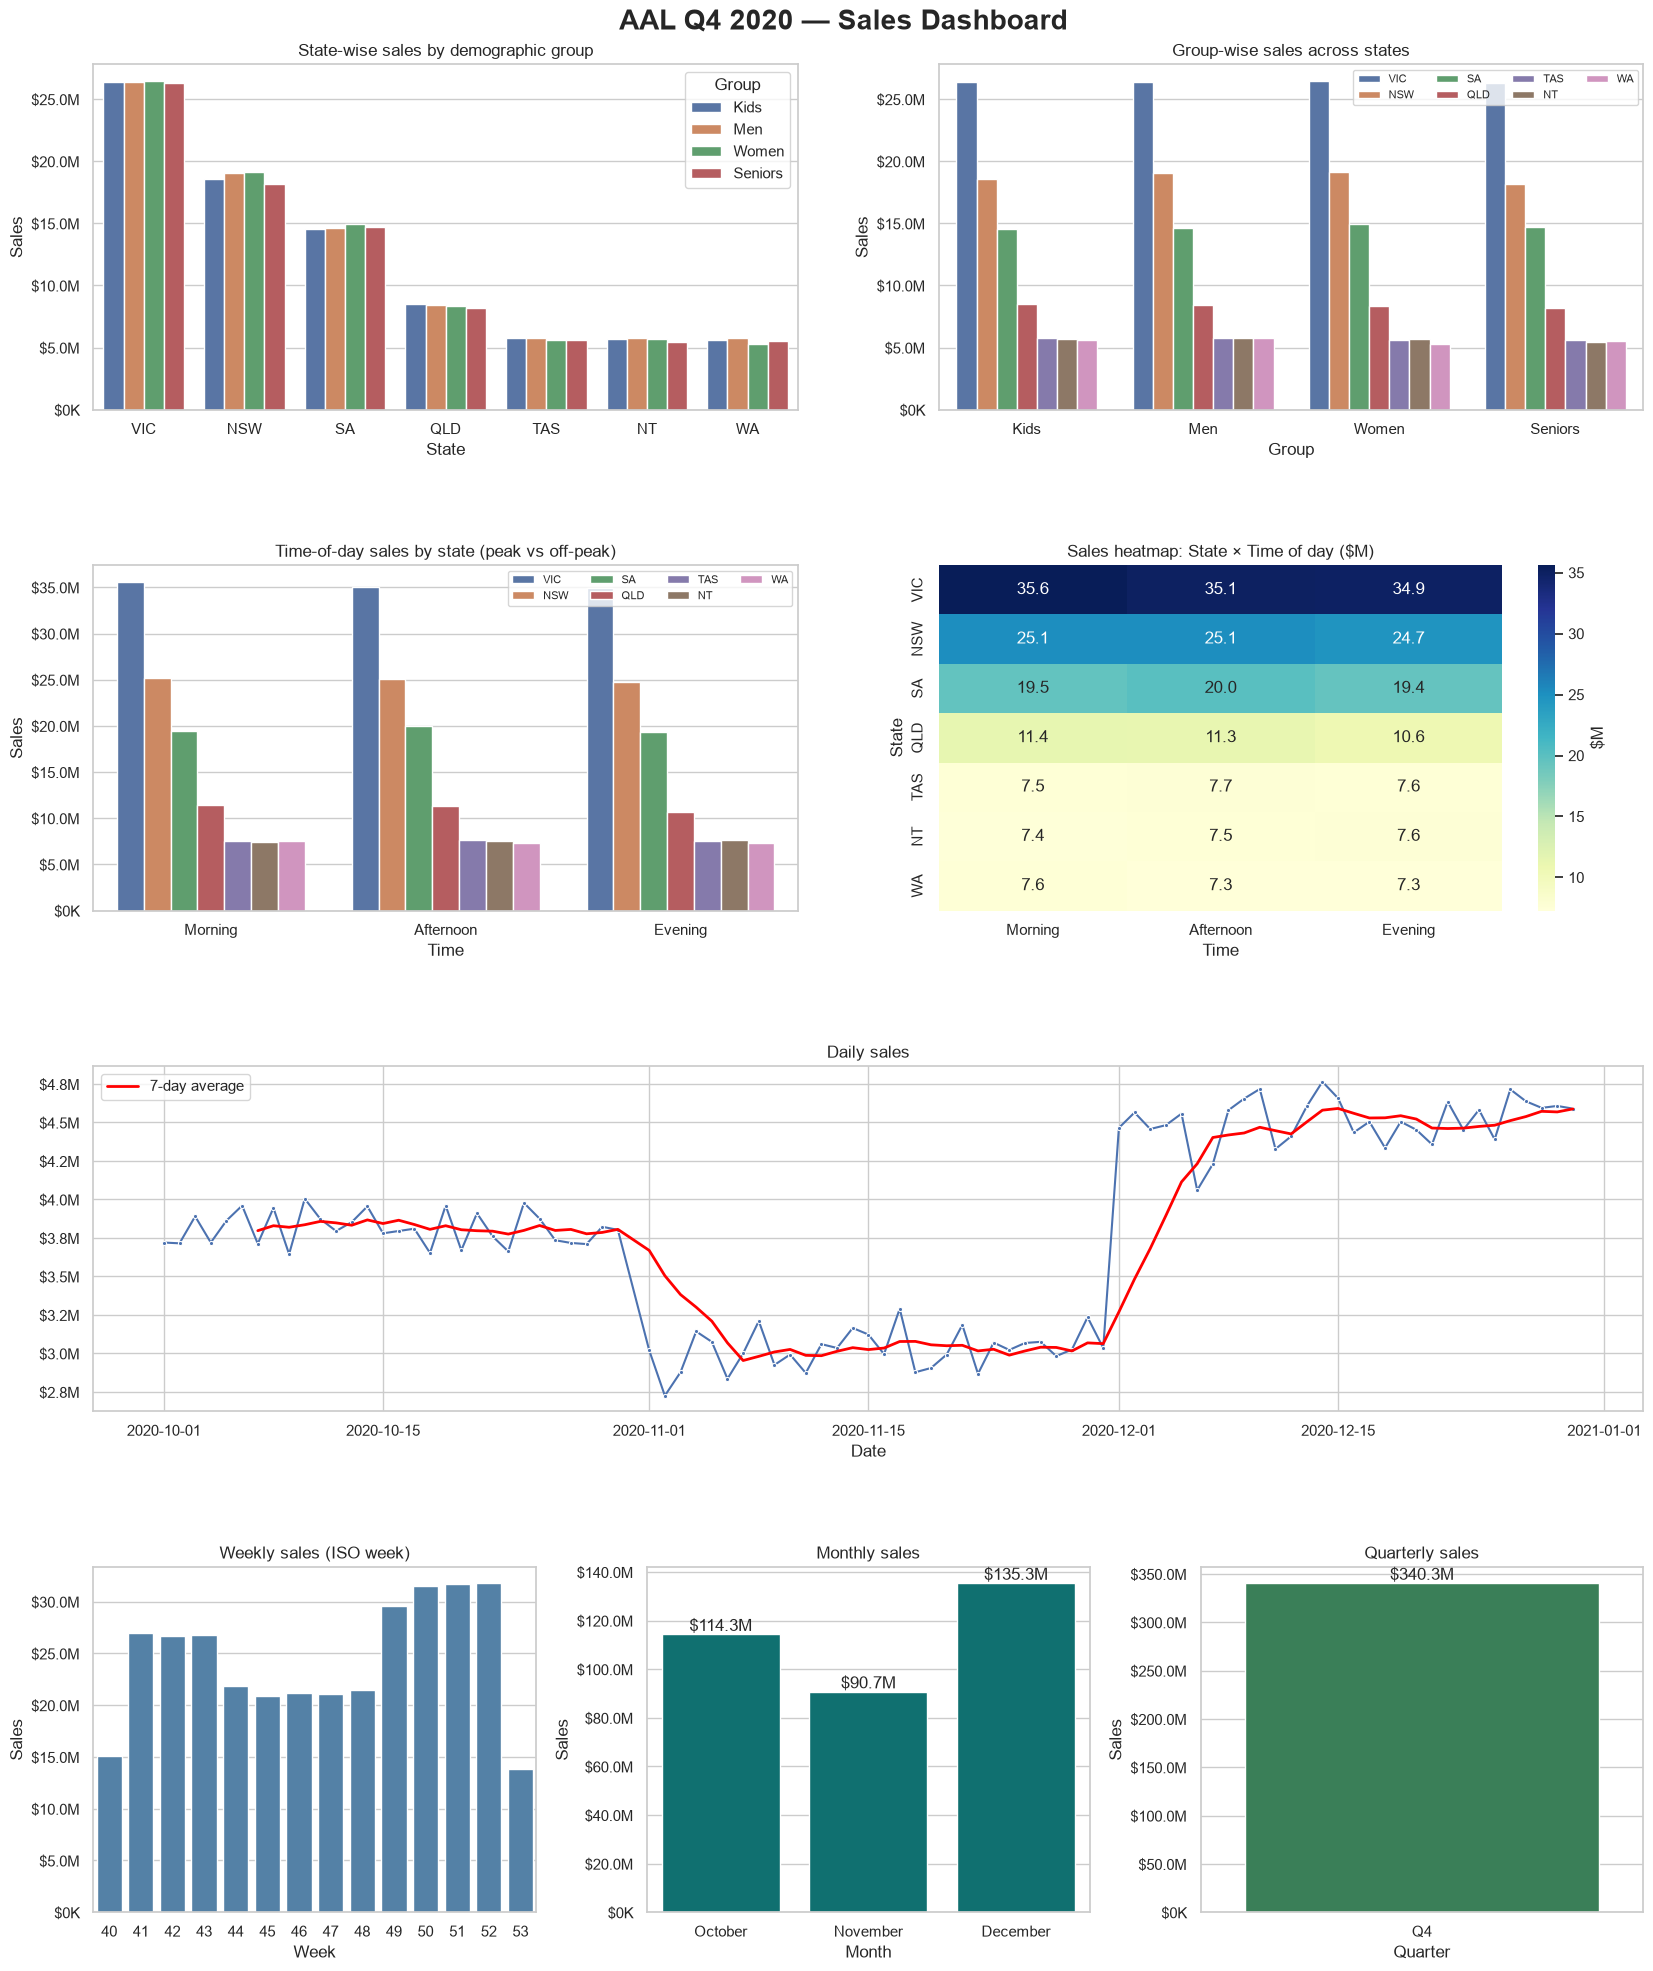

In [11]:
daily = df.groupby("Date")["Sales"].sum()
fig = plt.figure(figsize=(20, 22))
gs = fig.add_gridspec(4, 2, hspace=0.45, wspace=0.2, top=0.95)
fig.suptitle("AAL Q4 2020 — Sales Dashboard", fontsize=20, fontweight="bold", y=0.975)

# State-wise sales by demographic group
ax = fig.add_subplot(gs[0, 0])
sns.barplot(data=df, x="State", y="Sales", hue="Group", estimator=sum, errorbar=None, order=state_sales.index, ax=ax)
ax.set_title("State-wise sales by demographic group"); ax.yaxis.set_major_formatter(money)

# Group-wise sales across states
ax = fig.add_subplot(gs[0, 1])
sns.barplot(data=df, x="Group", y="Sales", hue="State", estimator=sum, errorbar=None, hue_order=state_sales.index, ax=ax)
ax.set_title("Group-wise sales across states"); ax.yaxis.set_major_formatter(money); ax.legend(ncol=4, fontsize=8)

# Time of day
ax = fig.add_subplot(gs[1, 0])
sns.barplot(data=df, x="Time", y="Sales", hue="State", estimator=sum, errorbar=None, order=["Morning", "Afternoon", "Evening"], hue_order=state_sales.index, ax=ax)
ax.set_title("Time-of-day sales by state (peak vs off-peak)"); ax.yaxis.set_major_formatter(money); ax.legend(ncol=4, fontsize=8)

ax = fig.add_subplot(gs[1, 1])
heat = df.pivot_table(index="State", columns="Time", values="Sales", aggfunc="sum")[["Morning", "Afternoon", "Evening"]].loc[state_sales.index] / 1e6
sns.heatmap(heat, annot=True, fmt=".1f", cmap="YlGnBu", ax=ax, cbar_kws={"label": "$M"})
ax.set_title("Sales heatmap: State × Time of day ($M)")

# Daily
ax = fig.add_subplot(gs[2, :])
sns.lineplot(x=daily.index, y=daily.values, ax=ax, marker="o", markersize=3)
ax.plot(daily.index, daily.rolling(7).mean(), color="red", lw=2, label="7-day average"); ax.legend()
ax.set_title("Daily sales"); ax.yaxis.set_major_formatter(money)

# Weekly / Monthly / Quarterly
sub = gs[3, :].subgridspec(1, 3, wspace=0.25)
ax = fig.add_subplot(sub[0]); sns.barplot(x=weekly.index.astype(str), y=weekly["Sales"], color="steelblue", ax=ax)
ax.set_title("Weekly sales (ISO week)"); ax.yaxis.set_major_formatter(money)
ax = fig.add_subplot(sub[1]); sns.barplot(x=monthly.index, y=monthly["Sales"], color="teal", ax=ax)
ax.set_title("Monthly sales"); ax.yaxis.set_major_formatter(money); ax.bar_label(ax.containers[0], labels=[f"${v/1e6:.1f}M" for v in monthly["Sales"]])
ax = fig.add_subplot(sub[2]); sns.barplot(x=quarterly.index, y=quarterly["Sales"], color="seagreen", ax=ax)
ax.set_title("Quarterly sales"); ax.yaxis.set_major_formatter(money); ax.bar_label(ax.containers[0], labels=[f"${v/1e6:.1f}M" for v in quarterly["Sales"]])
plt.show()

### Distribution plots (Seaborn)

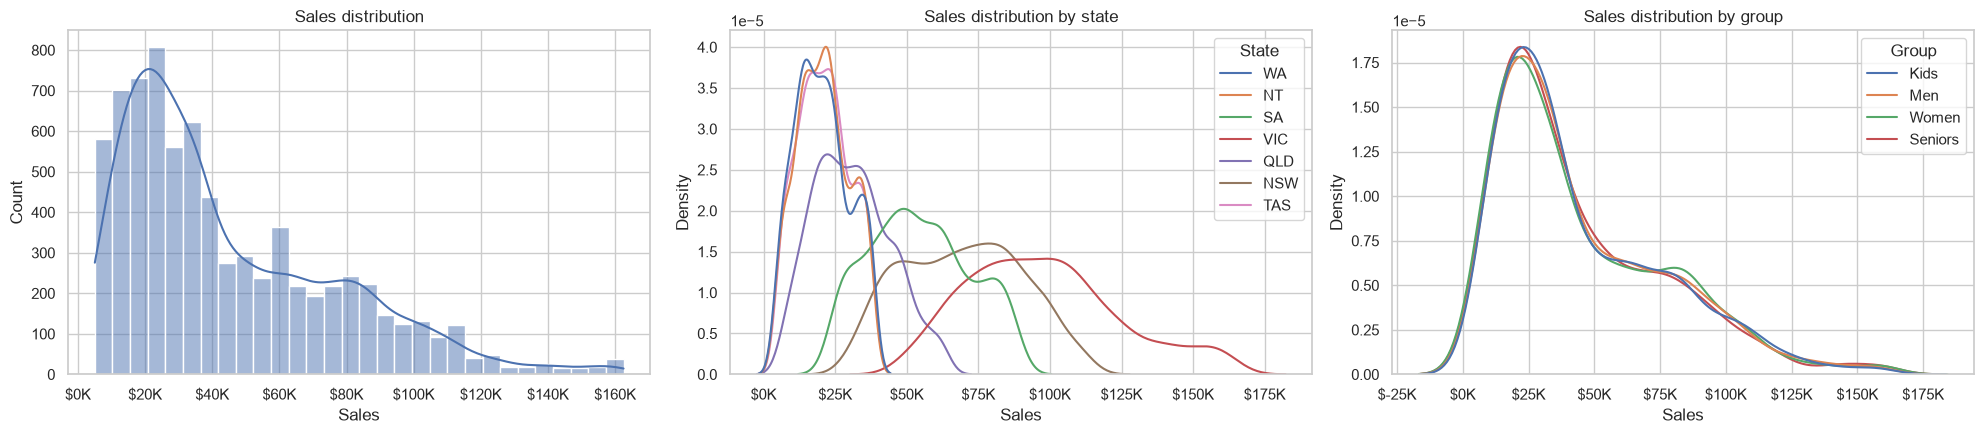

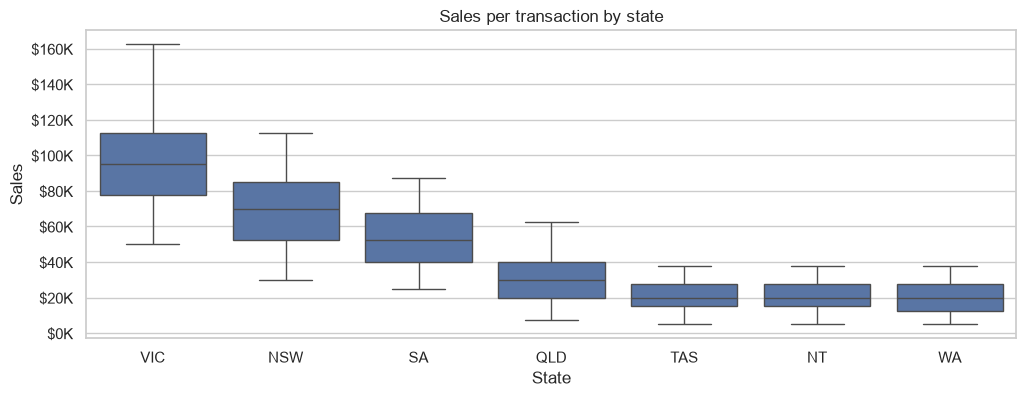

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(20, 4.5))
sns.histplot(df["Sales"], kde=True, ax=axes[0], bins=30); axes[0].set_title("Sales distribution"); axes[0].xaxis.set_major_formatter(money)
sns.kdeplot(data=df, x="Sales", hue="State", ax=axes[1], common_norm=False); axes[1].set_title("Sales distribution by state"); axes[1].xaxis.set_major_formatter(money)
sns.kdeplot(data=df, x="Sales", hue="Group", ax=axes[2], common_norm=False); axes[2].set_title("Sales distribution by group"); axes[2].xaxis.set_major_formatter(money)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(12, 4))
sns.boxplot(data=df, x="State", y="Sales", order=state_sales.index, ax=ax); ax.yaxis.set_major_formatter(money)
ax.set_title("Sales per transaction by state"); plt.show()

## 4. Insights & recommendations

In [13]:
print(f"Total Q4 revenue: ${df['Sales'].sum():,.0f}")
print("Revenue share by state (%):\n", state_summary["Share_%"])
print(f"\nPeak time slot: {time_sales.idxmax()} | Off-peak: {time_sales.idxmin()}")
print(f"Best month: {monthly['Sales'].idxmax()} | Weakest month: {monthly['Sales'].idxmin()}")

Total Q4 revenue: $340,302,500
Revenue share by state (%):
 State
VIC    31.0
NSW    22.0
SA     17.3
QLD     9.8
TAS     6.7
NT      6.6
WA      6.5
Name: Share_%, dtype: float64

Peak time slot: Morning | Off-peak: Evening
Best month: December | Weakest month: November


**Key insights**
* **Highest revenue:** **VIC** is the clear leader (~31% of revenue, $105.6M), followed by **NSW** (~22%) and **SA** (~17%).
* **Lowest revenue:** **WA** ($22.2M), **NT** and **TAS** each bring only ~6.5% — together about 20%, less than VIC alone. **QLD** (~10%) is mid-to-low.
* **Demographic groups** perform almost identically (Kids, Women, Men, Seniors each ≈ 25%) — no group is under-served nationally.
* **Time of day:** **Morning** is the (marginal) peak and **Evening** the off-peak; the gap is under 2%, so staffing can stay fairly even.
* **Seasonality:** sales fell ~21% in **November** ($90.7M) and jumped ~49% in **December** ($135.3M, holiday season); weekly sales step up from week 49 (30 Nov) onward.
* The data covers 1 Oct – 30 Dec 2020 (90 days); ISO weeks 40 and 53 are partial weeks.

**Recommendations**
1. **Invest in expansion in VIC and NSW**, where demand is proven — add stores/inventory ahead of the December peak.
2. **Sales programs for WA, NT, TAS (and QLD):** targeted promotions, loyalty schemes and online/click-and-collect to reach dispersed populations; test pop-up stores before full investment.
3. **Hyper-personalisation / Next Best Offer:** push offers in the off-peak **evening** slot and during the **November** lull to smooth demand.
4. **Plan inventory around the December surge** and start holiday campaigns in late November.